<center>
    <h2>Master 2</h2>
    <h5 style="margin-top: 5px">Sciences de l’Océan, de l’Atmosphère et du Climat</h5>
    <h1>TP - Simulations climatiques</h1>
  <br>
    <strong>Contact:</strong> isaline.bossert@meteo.fr / romain.torres4@gmail.com / gwenael.martin@meteo.fr

</center>


<div style="padding: 1rem; background-color: #d1ecf1; border: 1px solid #bee5eb; border-radius: 4px; margin: 1rem 0;">
  <strong>💡 Instructions</strong> 
    
Ce notebook est à <i>compléter</i> avec vos réponses aux questions posées et à <i>envoyer</i> par mail au plus tard <u>une semaine après la dernière séance de TP</u>. Merci de renommer le notebook pour y incorporer vos noms de famille (ex: TP-Climat-2026-Nom1_Nom2_Nom3.ipynb)
  - une attention particulière doit être donnée aux <b>figures</b> (clareté, titre, axes, légendes, etc..) 
  - les analyses portent sur vos <b>connaissances théoriques</b> en lien avec le cours "Système Climatique" (J. Cattiaux) sont attendues
  - la <b>curiosité scientifique</b> est bien sûre encouragée: même si les questions sont là pour aiguiller le TP, n'hésitez pas à demander des clarifications où d'éventuelles pistes d'analyses supplémentaires ;)
    

⚠️ Lors de la dernière séance, chaque groupe présentera son notebook (sujet + analyses effectuées):
  - durée max de 15 minutes de restitution qui doit être <b>claire</b> et <b>synthétique</b>. Il n'est pas nécessaire de créer un support de présentation particulier.
  - la restitution est suivie d'un <b>tour de questions</b> de la part des élèves puis des enseignantes pour vérifier les notions

<center>
        <h1>Sujet 2: Changement climatique anthropique actuel</h1>
  <br>
    <strong>Main topics covered here:</strong>
    <br>
    Climate system and energy balance (c.f. Cours 1)
    <br>
    Internal variability (c.f. Cours 2) 
    <br>
    Observed climate change (c.f. Cours 5)

</center>

## Introduction

Human activities generate a _radiative forcing_ on the climate system, mostly by increasing greenhouse gas concentration in the atmopshere.
A radiative forcing applied to the climate system must result in a climate change which tends to counteract the forcing.
Understanding how the Earth's climate changes to greenhouse gas forcing is essential for climate adaptation and mitigation.

In order to simulate recent climate changes, general circulation models, such as CNRM-CM6-1, can be forced by a suite of common data sets that are largely based on observations. These data sets represent external forcing and boundary conditions of the climate system.

Historical simulations (from 1850 to present day) are conducted by climate modelling groups and serve as a benchmark for assessing model performance through evaluation against observations.

In this notebook, you will analyze the climate response to quadrupling CO$_2$ concentration using outputs from the CNRM-CM6-1 model [(Voldoire et al., 2019)](https://doi.org/10.1029/2019MS001683). CNRM‐CM6‐1 is a fully coupled atmosphere‐ocean general circulation model of sixth generation jointly developed by Centre National de Recherches Météorologiques (CNRM) and Cerfacs for the sixth phase of the Coupled Model Intercomparison Project 6 (CMIP6).
In addition to the atmosphere and ocean circulations, it includes several climate components such as land surface, sea-ice and river routing ([Fig. 2](#tp1-fig2)). The model can be run in greenhouse gases concentration mode, allowing to fix atmospheric CO$_2$ levels. 

In particular, you will:
  - use model of Earth energy equation to show the differences between an equilibrated and non-equilibrated climate
  - compute the climate sensitivity, which measures the strength of the temperature response to radiative forcing
  - highlight climate feedbacks
  - discuss your results using other climate models


<br>

<div align="center">
    <div id="tp1-fig1" style="width: 550px; float: left">
        <img src="../figures/Zhang_and_Chen-2024-CO2_in_CMIP_experiments.png" alt="drawing" width="500"/>
    </div>
    <div style="width: 300px; float right">
        <img src="../figures/Voldoire-2019-CNRM-CM6-1.png" alt="drawing" width="400"/>
    </div>
    <br>
    <div>
    <div id="tp1-fig2" style="width: 550px; float: left">
    <b>Fig. 1. </b>Changes in CO2 concentration in different climate model experiments. The large dot on each line indicates the year of maximum concentration. For the abrupt quadrupling of CO2 experiment (abrupt-4xCO2), the CO2 concentration maximum year is labeled as the first year of the 150 year period between 1850 and 1999. Taken from <a href="https://doi.org/10.1007/s00382-024-07397-7">Zhang and Chen (2024)</a>.
    </div>
    <div style="width: 300px; float right">
    <b>Fig. 2. </b>CNRM-CM6-1 schematic and all its components. Taken from <a href="https://doi.org/10.1029/2019MS001683">Voldoire et al. (2019)</a>.
    </div>
    </div>
</div>

<br><br><br><br>

## Load Python modules and simulation outputs

Along this notebook, Python codes are used to analyse model outputs.
You first need to import and load required modules:

In [1]:
# manipulate file and data
import cftime
import os
import scipy
import numpy  as np
import xarray as xr

# plotting
import matplotlib
import matplotlib.pyplot as plt

<a id="section-1"></a>
## 1. Current climate change  

In this section, we will first analyze some observation-based data sets highlighting climate change, before moving into historical simulations of the CNRM-CM6-1 model.

- Greenhouse gases emission and forcing; how do we know about GHG emission ?
- Temperature evolution, how it is observed ?

#### Question 1: 

* _After having define relevent timescales, list external forcings that have to be considered to drive climate model for the historical period (1850-2020)._
* _How do they atler the Earth energy balance ? What effect is known to dominate ?_

__Help__: you can insert Latex math code using '$' symbols and insert image using html code:
```html
<img src="image.png" alt="drawing" width="400"/>
```


<font color="blue">

Studying climate change involves multiple timescales (from year to millions of years). 
However current observed climate change (the one relevent for human society and for most of ecosystems) is relevent for decades and centuries (perhaps millenia but not on geological timescales).

Thus, the main external focrings that should be considered here are rapid changes in solar energy input, greenhouse gases atmospheric concentration, aerosols (both natural and anthropique) and land use changes.
    
We can define the Earth climate system as the solid Earth plus liquid and solid waters (ocean, rivers, lake and cryosphere) and the atmosphere, which encompasses all the other components. The energy budget is written by summing energy inputs and outputs at the system boundary, which is here the top of the atmopshere: 
    $$\Delta R = \left(1-\alpha\right)S_0/4 - \sigma T_e^4 \,$$
    
At the equilibrium, $\Delta R = 0$. But this equilibrium can be perturbed by external forcings above-listed:
    
    
  - solar energy income can vary on multiple timescale. Solar emissions exhibit a ~11 years cycle (Schwabe cycle) in which variation of $S_0$ reach about 1 W.m-2. Solar flares and sunspots can also altered $S_0$ locally. However, slower energy changes (e.g. sun's growth that takes billion years) are far too slow to be considered here.
    
    
  - the main greenhouse gases to be considered are carbon dioxide (CO$_2$), methane (CH$_4$) and nitrous oxide (N$_2$O). Concentration changes are the result of a change in the balance between emissions (sources) and sinks. CO$_2$ emissions could be natural (around 0.08 GtC/year due to volcanic activity) or anthropic (~11 GtC/year due to current humain activity). In addition, other greenhouse gase emissions leads to about ~3.8 GtC/year (converted in equivalent CO$_2$ emission). Increase in carbon sinks in not enough to compensate emissions, so that atmospheric concentration in greenhouse gases increases resulting in a positive external forcing.
    - _How does this work ?_ 
    The absorptivity of the atmosphere is yet close to 1, i.e., almost all upward longwave radiation is absorbed. Increasing the amount of greenhouse gases therefore has only a relatively marginal effect on absorptivity: it is only increased at wavelengths where opacity is not already total. However, the addition of greenhouse gases have an impact on the amount of radiation emitted at the top of the atmosphere ($\sigma T_e^4$). Due to the negative temperature gradient in the troposphere, an increase of CO$_2$ leads to a reduction of $T_e$ (the atmosphere layer that emit longwave is higher in altitude). This results in a gain of energy in the climate system warming the troposphere where the temperature gradient is shifted to reach a new equilibrium (leading to an increase of the surface temperature).
    
    
  - Aerosol are fine solid particles or liquid droplets in suspension in the atmosphere, with short lifetimes and are generally locally concentrated. Main group are sulfates and black carbon. As part of the air chimical composition, they can have a direct impact on the absorption and diffusion, hence altering the upward longwave emission flux (in a similar manner that greenhouse gases). In addition, thet alter cloud formation, which have in turn a radiative effect in both the longwave (change in $T_e$) and shortwave fluxes (through the total albedo $\alpha$).
    
    
  - Rapid land use changes are due to human land management (deforestation, reforestation, agriculture, etc..) that change the surface albedo, hence altering the solar reflection throug $\alpha$. Note that indirect causes such as fires can also change surface albedo. In total, land use changes tend to increase albedo (replacement of dark forest to clearer agricol surfaces).
    

All in all, the sum of the external forcing is estimated to be about 2.9$\pm$0.7 W.m-2, mostly due to greenhouse gases forcing, for which CO$_2$ is the most important one.
    
    
<img src="../figures/Forster-2023-External_forcing.png" alt="drawing" width="700" style="margin-bottom:-350px;"/>
    
</font>

#### Question 2: 

* _Plot a figure showing the temporal evolution of the different greenhouse gases concentration._
* _What do you observed ?_


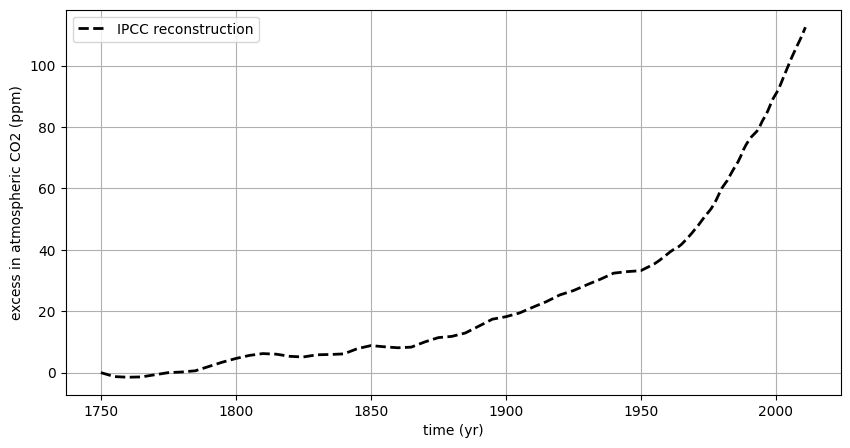

In [2]:
# TODO: change with CMIP6 GHG forcing file

import csv

# load atmospheric CO2 reconstruction by IPCC
CO2_ipcc = np.array([line for line in csv.reader(open('../data/HistAtmo_IPCC.1750-2011.CO2.csv','r'))],dtype=float)[:,0] #{ppm}

plt.figure(figsize=(10, 5))
plt.plot(np.arange(1750,1750+len(CO2_ipcc)),CO2_ipcc-CO2_ipcc[0],color='k',lw=2,ls='--',label='IPCC reconstruction')
plt.ylabel('excess in atmospheric CO2 (ppm)')
plt.xlabel('time (yr)')
plt.grid(True)
plt.legend(loc=0)

<font color="blue">

CO$_2$ should dominates, but how to compare different species concentration ? maybe introduce the equivalent CO2 here
    
</font>

#### Question 3: 

* _Plot a figure showing the temporal evolution of the different type of fossil CO2 emissions._
* _Comment on the choice of the year 1850 to start historical climate change simulation._


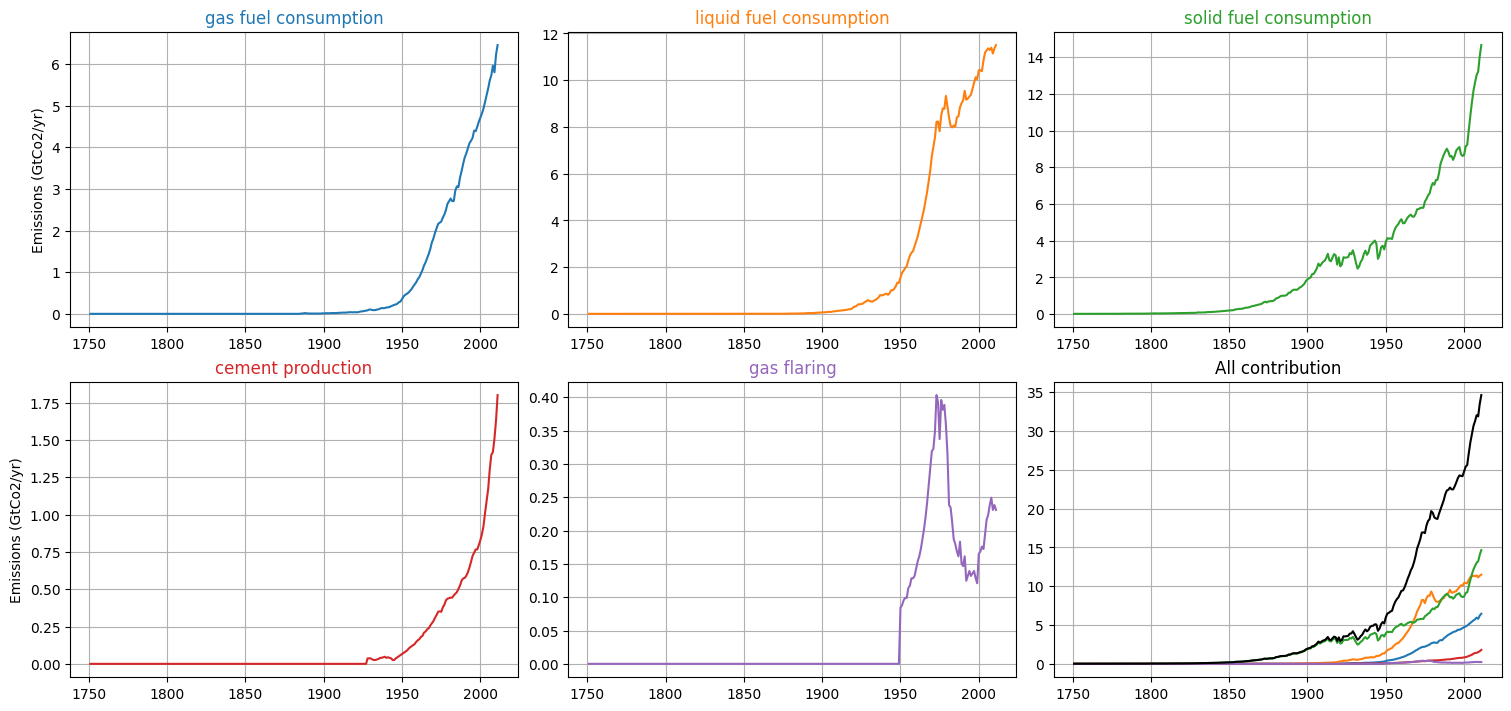

In [3]:
import csv 

# load the historical data on fossil CO2 emissions
EFF_type = np.array([line for line in \
    csv.reader(open("../data/CDIAC_EFF.global.1751_2011.csv","r"))][2:],dtype=float)[:,2:-1] / 1000 * 44/12. #{GtCO2/yr}
EFF_lgd = [line for line in \
    csv.reader(open("../data/CDIAC_EFF.global.1751_2011.csv","r"))][0][2:-1]
EFF = np.sum(EFF_type,1)

# use the IRF to simulate past changes in atmospheric CO2 conversion factor
k_CO2 = 2.13 * 44 / 12 #{GtCO2/ppm}

fig, axs = plt.subplots(2, 3, layout='constrained', figsize=(15, 7))
gridspec = axs[0, 0].get_subplotspec().get_gridspec()

colors   = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple'] 

for i in range(len(EFF_lgd)):
    lgd = EFF_lgd[i]
    typ = EFF_type[:,i]
    col = colors[i]

    ax  = axs[i//3, i%3] 

    ax.set_title(lgd.split('Carbon emissions from ')[1], y=1, color=col)
    ax.plot(np.arange(1751, 1751+len(typ)), typ, color=col)

    axs[1,2].plot(np.arange(1751, 1751+len(typ)), typ, color=col, label=lgd)

    ax.grid(True)

    if i%3 == 0:
        ax.set_ylabel("Emissions (GtCo2/yr)")


axs[1,2].set_title('All contribution')
axs[1,2].plot(np.arange(1751, 1751+len(EFF)), EFF, color='k', label='total')

axs[1,2].grid(True)

<font color="blue">

CO$_2$ emissions are exponentially growing and started at different periods. The earliest emissions come from solid fuel and started during the 19th century (industrial revolution). Other emessions are more recent (e.g. cement production and gas flaring). 
    
Before, 1850 almost no CO$_2$ have been emitted due to human activity. It is therefore a natural choice to started simulation of climate change.
    
</font>

#### Question 4: 

The increase in greenhouse gase concentration exerts a positive radiative forcing on the climate system. As a result, the climate system must exhibit changes to balance this external forcing. Since the system gains energy, it is expected that its temperature should increase. Because surface temperature is a relatively well observed variable, it is therefore the natural choice to track climate change.   

* _Plot a figure showing the temporal evolution of the global surface air temperature (over land and ocean) and compute the temperature change from the pre-industrial state._
* _How the temperature has evolved ? Comment on the uncertainty range._


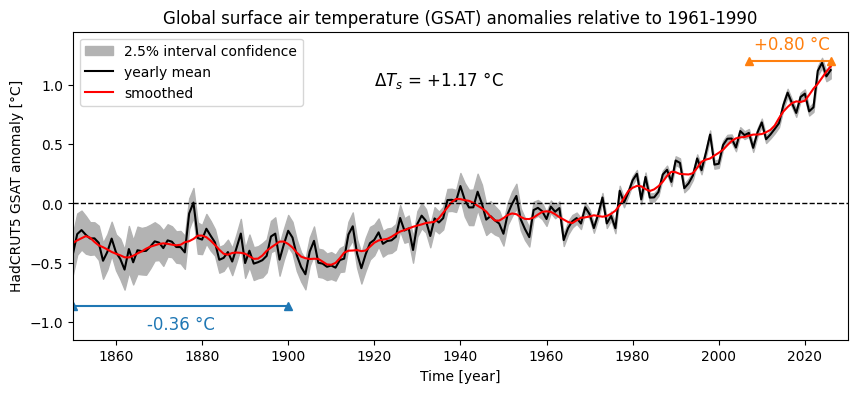

In [4]:
import statsmodels.api as sm

HadCrut4 = xr.load_dataset('../data/OBSERVATIONS/HadCRUT.GSAT.4.6.0.0.median.nc', use_cftime=True)
HadCrut5 = xr.load_dataset('../data/OBSERVATIONS/HadCRUT.5.2.0.0.analysis.summary_series.global.annual.nc', 
                                                                                                use_cftime=True)

GSAT_4   = HadCrut4['temperature_anomaly']
GSAT_ym  = GSAT_4.groupby('time.year').mean()
GSAT_sm  = sm.nonparametric.lowess(exog=GSAT_ym['year'], endog=GSAT_ym, frac=0.05)

years    = np.array([d.year for d in HadCrut5['time'].data])
GSAT     = HadCrut5['tas_mean']
GSAT_low = HadCrut5['tas_lower']
GSAT_upp = HadCrut5['tas_upper']
GSAT_sm  = sm.nonparametric.lowess(exog=years, endog=GSAT, frac=0.05)


# plot GSAT anomalies
fig, ax = plt.subplots(1,1, figsize=(10, 4))

ax.fill_between( years, GSAT_upp, GSAT_low, color=(.7,.7,.7), label='2.5% interval confidence')
ax.plot(         years, GSAT,               color='k',        label='yearly mean')
ax.plot(  GSAT_sm[:,0], GSAT_sm[:,1],       color='r',        label='smoothed')


# compute GSAT changes
GSAT_pi = GSAT[:50].mean()    # pre_industrial
GSAT_pd = GSAT[-20:].mean()   # present day

ax.plot( [1850, 1900], [GSAT_pi-0.5]*2, ls='-', marker='^')
ax.plot( [2007, 2026], [GSAT_pd+0.4]*2, ls='-', marker='^')

ax.text( 1875, GSAT_pi-0.7, r"{:.2f} °C".format(GSAT_pi),  ha='center',fontsize=12,  c='tab:blue')
ax.text( 2017, GSAT_pd+0.50, r"+{:.2f} °C".format(GSAT_pd), ha='center',fontsize=12,  c='tab:orange')
ax.text( 1935, 1.0, r"$\Delta T_s$ = +{:.2f} °C".format(GSAT_pd-GSAT_pi), ha='center', fontsize=12,  c='k')

# plot zero line
ax.plot( [1850, 2050], [0, 0], lw=1., ls='--', c='k')

# axe properties
ax.set_xlim((1850, 2030))
ax.set_ylim((-1.15, 1.45))
ax.set_xlabel('Time [year]')
ax.set_ylabel('HadCRUT5 GSAT anomaly [°C]')

ax.legend()

_ = ax.set_title("Global surface air temperature (GSAT) anomalies relative to 1961-1990")

<font color="blue">

First of all, global surface air temperature (GSAT) time series show a marked natural variability as seen by noise in the yearly-averaged data set. There is also some sort of decadal variability. However, the time serie contain sufficient data (more than 150 years) to interpret the signal temperature change.

At the begening, the GSAT is relatively stable until at least year 1900; the ratio noise-signal is high so that it is impossible to detect any changes. During the 20th century, the GSAT increase first and then stabilize from 1950 to 1980. Again, while greenhouse gases concentration have increased, the signal of GSAT growth is still relatively low; it is therefore difficult to seperate the signal from natural variability. Nevertheless, from the end of the 20th century, the signal is clear: the GSAT has increased almost linearly until today (this even seems to intensify at the end of the time serie).
    
All in all, we can compute a temperature change $\Delta T_s$ from two different period. To avoid including natural variability in the calculation it is recommended to use large period average (usually several decades). Here we computed a +1.17°C surface warming by selecting a 20 years period (2007-2026) relative to 1850-1900. 
    
Here we can set a word on the uncertainty. The data set provide a lower and upper range og the GSAT anomaly, thus giving an uncertainty range. It is worthnoting that this range progressively reduces, in particular from the midlle of the 20th century and is now very small. Sources of uncertainty include (see details in [Morice et al., (2020)](https://doi.org/10.1029/2019JD032361) :
  - spatial and temporal sampling of the globe
  - changes in measurement practice and instrumentation
  - siting of observing stations and the effects of changes in their nearby environment
  - basic measurement error
    
It is also important to note how this data set is created. In particular, it is a merge between sea surface temperature (HadSST4) and near-surface air temperature (CRUTEM5). How observation of both metrics have evolved since 1850 :
  - SST: is mainly the aggregation of in-situ measurements from ships and drifting buoys (spatial converage has been greatly improved since 1850); plus satelitte allow now a continuity in a quasi-global context even if satellite recors are not included in HadSST. Temperature sensors have also improved in quality. 
  - Land: mainly from temperature measures of weather stations; again the spatial coverage passed from European stations only to a more global temperature measures. Also the gridded method and quality check can also have changed; same remark regarding the satellite radiometric measurement. 
    
</font>

#### Question 5: 

We will now try to spartialize (e.g. north vs. south, land vs ocean) surface temperature changes over the Earth.

* _Use the variables to create regionally-focused time series of surface temperature changes._
* _From your knowledge of climate dynamics, try to explain the differences observed ?_


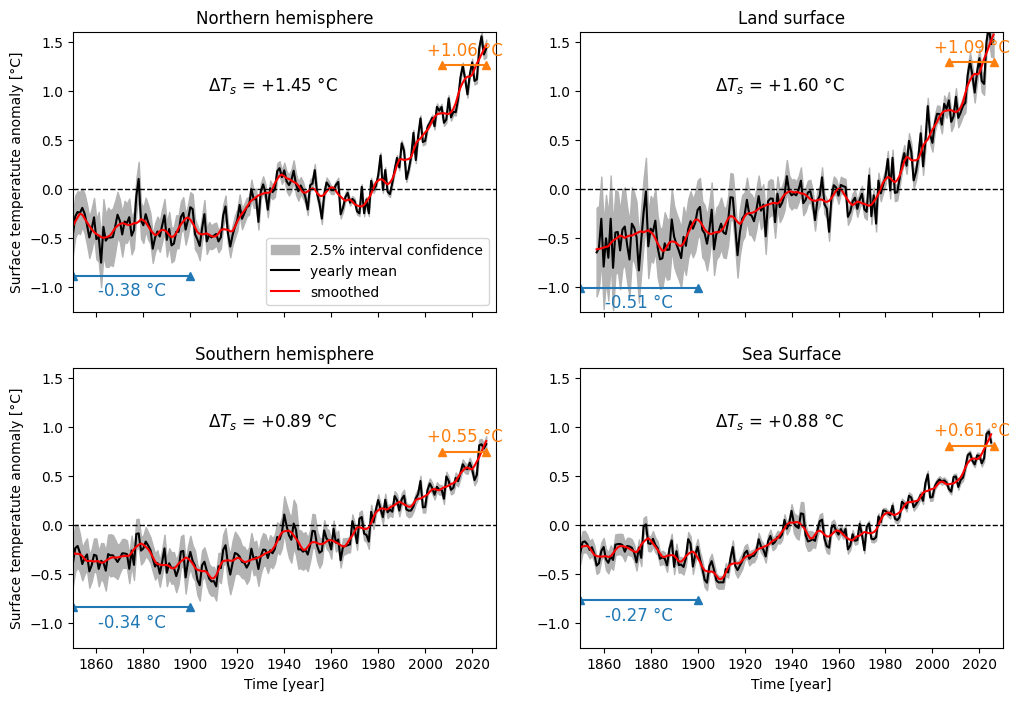

In [5]:
import statsmodels.api as sm

HadCrut5_north = xr.load_dataset(
    '../data/OBSERVATIONS/HadCRUT.5.2.0.0.analysis.summary_series.northern_hemisphere.annual.nc',
    use_cftime=True)

HadCrut5_south = xr.load_dataset(
    '../data/OBSERVATIONS/HadCRUT.5.2.0.0.analysis.summary_series.southern_hemisphere.annual.nc',
    use_cftime=True)

CRUTEM5 = xr.load_dataset(
    '../data/OBSERVATIONS/CRUTEM.5.2.0.0.summary_series.global.annual.nc',
    use_cftime=True)

HadSST_arr = np.loadtxt('../data/OBSERVATIONS/HadSST.4.2.0.0_annual_GLOBE.csv', delimiter=',', skiprows=1)
HadSST_yr  = np.array(
    [cftime.DatetimeGregorian(y, 7, 2, 12, 0, 0, 0, has_year_zero=False) for y in HadSST_arr[:,0]]
    )

HadSST4    = xr.Dataset()
HadSST4['tos']       = xr.DataArray(data=HadSST_arr[:, 1], dims=('time'), 
                              coords={'time': HadSST_yr})
HadSST4['tos_lower'] = xr.DataArray(data=HadSST_arr[:, 1]-HadSST_arr[:, 2], dims=('time'), coords=HadSST4.coords)
HadSST4['tos_upper'] = xr.DataArray(data=HadSST_arr[:, 1]+HadSST_arr[:, 2], dims=('time'), coords=HadSST4.coords)


# plot regional temperature anomalies
fig, axes = plt.subplots(2,2, figsize=(12, 8))

for i, ds in enumerate([HadCrut5_north, HadCrut5_south, CRUTEM5, HadSST4]):
    ax = axes[i%2,i//2]
    
    # get years
    years    = np.array([d.year for d in ds['time'].data])

    # get temperature variable
    if 'tas_mean' in ds.variables:
        tasm     = ds['tas_mean']
        tasm_low = ds['tas_lower']
        tasm_upp = ds['tas_upper']
    
    elif 'tas' in ds.variables:
        tasm     = ds['tas']
        tasm_low = ds['tas_lower']
        tasm_upp = ds['tas_upper']
        
    elif 'tos' in ds.variables:
        tasm     = ds['tos']
        tasm_low = ds['tos_lower']
        tasm_upp = ds['tos_upper']
    
    else:
        continue
    
    tasm_sm  = sm.nonparametric.lowess(exog=years, endog=tasm, frac=0.05)
    
    # plot on axe
    ax.fill_between( years, tasm_upp, tasm_low, color=(.7,.7,.7), label='2.5% interval confidence')
    ax.plot(         years, tasm,               color='k',        label='yearly mean')
    ax.plot(  tasm_sm[:,0], tasm_sm[:,1],       color='r',        label='smoothed')


    # compute tas_mean changes for each region
    tasm_pi = tasm[:50].mean()    
    tasm_pd = tasm[-20:].mean()

    ax.plot( [1850, 1900], [tasm_pi-0.5]*2, ls='-', marker='^')
    ax.plot( [2007, 2026], [tasm_pd+0.2]*2, ls='-', marker='^')

    ax.text( 1875, tasm_pi-0.7, r"{:.2f} °C".format(tasm_pi),  ha='center',fontsize=12,  c='tab:blue')
    ax.text( 2017, tasm_pd+0.3, r"+{:.2f} °C".format(tasm_pd), ha='center',fontsize=12,  c='tab:orange')
    ax.text( 1935, 1.0, r"$\Delta T_s$ = +{:.2f} °C".format(tasm_pd-tasm_pi), ha='center', fontsize=12,  c='k')

    # plot zero line
    ax.plot( [1850, 2050], [0, 0], lw=1., ls='--', c='k')

    # axe properties
    ax.set_xlim((1850, 2030))
    ax.set_ylim((-1.25, 1.6))
    
    if i%2 != 0:
        ax.set_xlabel('Time [year]')
    else:
        ax.set_xticklabels([])

axes[0,0].set_ylabel('Surface temperatute anomaly [°C]')
axes[0,0].set_title("Northern hemisphere")
axes[0,0].legend(loc=4)

axes[1,0].set_ylabel('Surface temperatute anomaly [°C]')
axes[1,0].set_title("Southern hemisphere")

axes[0,1].set_title("Land surface")

axes[1,1].set_title("Sea Surface")

_ = _

<font color="blue">

There is a clear difference between surface warming in the northern hemisphere (+1.45°C) and the southern hemisphere (+0.89°C). This can be explained by the Arctic sea ice retreat and the resulting higher warming there (albedo feedbacks). Interestingly, pre-industrial temperature is in average similar in both hemisphere, showing that present day hemispheric differences is due to current climate change and could be transcient. We can also note that uncertainty decrease before in the northern hemisphere reflecting the increase of weather stations in the richest occidental countries.
    
Warming is also greater over continent (+1.6 °C) than over the ocean (+0.88°C).
This can be explained by the heat capacity storage of the ocean (huge mass of water and high specific heat capacity) as well as by the ocean circulation that store heat in deeper layers.
    
</font>

#### Question 6: 

So far we have focus on the observed warming at the surface, only, but we know it exhibits some vertical structure. Here we will focus on the ocean component, which have absorbed the majority (about 91%) of the human-induced warming.

* _Plot ocean heat content time series during the last decades._
* _Propose a method to quantify the resulting Earth energy imbalance from time evolution of heat content._ 

__Help:__ we can assume that all the excess of energy has been absorbed by the ocean.

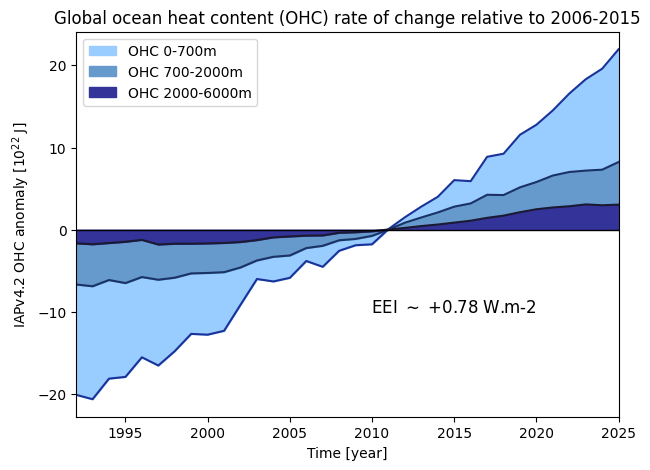

In [6]:
IAPv4    = xr.load_dataset('../data/OBSERVATIONS/IAPv4.2_OHC_estimate_update.nc',
    use_cftime=True)

IAPv4_yr = IAPv4.groupby('time.year').mean()

# plot GOHC anomalies
fig, ax = plt.subplots(1,1, figsize=(7, 5))


ax.fill_between( IAPv4_yr['year'], 
                 IAPv4_yr['ohc700']+IAPv4_yr['ohc700-2000']+IAPv4_yr['ohc2000-6000'], 
                 IAPv4_yr['ohc700-2000']+IAPv4_yr['ohc2000-6000'],
                 color=(.6,.8,1.), label='OHC 0-700m'
               )
ax.fill_between( IAPv4_yr['year'], 
                 IAPv4_yr['ohc700-2000']+IAPv4_yr['ohc2000-6000'], 
                 IAPv4_yr['ohc2000-6000'],
                 color=(.4,.6,.8), label='OHC 700-2000m'
               )
ax.fill_between( IAPv4_yr['year'], 
                 IAPv4_yr['ohc2000-6000'],
                 color=(.2,.2,.6), label='OHC 2000-6000m'
               )

ax.plot(IAPv4_yr['year'], IAPv4_yr['ohc2000']+IAPv4_yr['ohc2000-6000'],     c=(.1, .2, .6))
ax.plot(IAPv4_yr['year'], IAPv4_yr['ohc700-2000']+IAPv4_yr['ohc2000-6000'], c=(.1, .2, .4))
ax.plot(IAPv4_yr['year'], IAPv4_yr['ohc2000-6000'],                         c=(.1, .1, .2))

# compute Earth energy imbalance
OHC  = IAPv4_yr['ohc2000-6000'] + IAPv4_yr['ohc2000']
dOHC = OHC[-10:].mean() - OHC[52:52+10].mean()     # 24 years period here

Earth_radius  = 6371229
Earth_surface = 4 * np.pi * Earth_radius**2

EEI  = dOHC * 10**22 / (24 * 365.3 * 24 * 60 * 60) / Earth_surface

ax.text( 2015, -10, r"EEI $\sim$ +{:.2f} W.m-2".format(EEI), ha='center', fontsize=12,  c='k')


# plot zero line
ax.plot( [1850, 2050], [0, 0], lw=1., ls='-', c='k')

# axe properties
ax.set_xlim((1992, 2025))
ax.set_xlabel('Time [year]')
ax.set_ylabel(r'IAPv4.2 OHC anomaly [10$^{22}$ J]')

ax.legend()

_ = ax.set_title("Global ocean heat content (OHC) rate of change relative to 2006-2015")

<font color="blue">

Ocean heat content shows a large increase in the last decades, similar to the one observed from sea surface temperature. The most significant signal comes from the surface and intermediate layers (0-700m) but is found at every depths. This means that the whole ocean is warming mainly due to the overturning circulation and dynamical processes that mix water masses over depths.
    
It is also important to note that measurements of the ocean at depths are more recent (specially for the abyssal layer). One can also note the development of autonomous ARGO floats (started in 1999) that considerably improved the monitoring of the ocean heat content, while reducing uncertainty (not shown here).
    
Since most of the excess in energy du to external forcing is supposed to go to the ocean, one can derive the Earth energy imbalance (EEI), which is the radiative forcing $\Delta R$ in a non-equilibrated climate:
    $$ \Delta R = \frac{1}{S_\mathrm{earth}}\frac{\partial\,\mathrm{OHC}}{\partial t}$$

Assuming the radiative forcing has not change during the last two decades,or equivalently that the OHC increases linearly, we can deduce the EEI from the OHC averaged over two distinct periods (2017-2026 and 1992-2001):
    $$ \Delta R \sim \frac{1}{S_\mathrm{earth}}\frac{\Delta \mathrm{OHC}}{\Delta t}$$
    
  where we found a radiative forcing $\Delta R$ of about 0.78 W.m-2 in close agreement with the estimation of [von Schuckmann et al. (2020)](https://doi.org/10.5194/essd-12-2013-2020). However, here we have neglected the warming og other components (cryosphere, biosphere, atmopshere). Moreover, the hypothesis of a linear increase of the OHC is strong; indeed there is an acceleration of the ocean warming as recently proved by [Minière et al., (2023)](https://doi.org/10.1038/s41598-023-49353-1).

</font>

<a id="section-2"></a>
## 2. Simulation of historical period

The previous section has listed the external forcing that can explain recent and observed climate change (expressed as a global temperature increase).

Here, we will analyze simulations of the climate model CNRM-CM6-1 used to characterize climate evolution during the historical period (1850 to present day). In practice, this requires 1) to initialize the model from a pre-industrial climate state and 2) to follow time evolution of known external forcing (as seen in question 2).

Regarding 1), the initialization from a fixed and observed pre-industrail state is not possible for at least two reasons. First, observations before 1850 are extremly rare and sparse. Second, all climate models are biased and therefore can differ from observations, even if the imposed conditions are correct. Due to the diffetrent climate variability timescales (from season to centuries), it would be impossible to seperate the signal from t

For point 2) this needs to impose external forcing through the atmosphere composition in greenhouse gase and aerosols as well as other input such as sun radiation.    

- present piCtrl / concept of equilibration and drift
- internal variability
- concept of ensemble and members / model uncertainty 


In [7]:
# initialize empty dict to store variables
piCtrl = dict()
histrc = dict()

# load netCDF (.nc) files using xarray
for f in os.listdir("../data/CMIP6"):
    var   = f.split('_')[0]
    model = f.split('_')[2]
    expe  = f.split('_')[3]
    label = f.split('_')[4]
    
    # select only CNRM-CM6-1 model
    if model == 'CNRM-CM6-1':
        ds = xr.load_dataset(os.path.join("../data/CMIP6", f), use_cftime=True)
        
        if expe == 'piControl':
            piCtrl[var]      = ds[list(ds.variables)[-1]]
            piCtrl[var].name = var
            
        elif expe == 'historical':
            member           = histrc.setdefault(label.replace('i1p1f2', ''), dict())
            member[var]      = ds[list(ds.variables)[-1]]
            member[var].name = var

print("Variables loaded in piCtrl: \n", list(piCtrl.keys()))
print(len(histrc), "members loaded in histrc: \n", sorted(list(histrc.keys())) )

Variables loaded in piCtrl: 
 ['rsutcs', 'ts', 'snws', 'siextentn', 'snwn', 'siextents', 'lain', 'rsdt', 'rsut', 'rlut', 'lais', 'rlutcs']
27 members loaded in histrc: 
 ['r1', 'r10', 'r11', 'r12', 'r13', 'r14', 'r15', 'r16', 'r17', 'r18', 'r19', 'r2', 'r20', 'r21', 'r22', 'r24', 'r25', 'r27', 'r29', 'r3', 'r30', 'r4', 'r5', 'r6', 'r7', 'r8', 'r9']


Here we have used again the python module _xarray_ to load dataset. Each variable are store in python dictionnaries `piCtrl` and `histrc` for the _piControl_ and _historical_ experiments, respectively.
You can access to the data, by using the variable name:

```python
    piCtrl['ts']          # this return an xarray.DataArray object
    piCtrl['ts'].data     # this return an numpy.array object
    piCtrl['ts']['time']  # this return the 'time' coordinate for the variable 'ts'
```

The `histrc` dictionnary contains several subdictionnaries, each of them refers to one member of the historical CNRM-CM6-1 ensemble runs. You can check the branch time in the dataset attribues `histrc['r1'].attrs['branch_time_in_parent']` with units defined in `histrc['r1'].attrs['parent_time_units]`.

Note that _piControl_ experiment has monthly ouput, and therefore exhibit seasonal cycle. In order to filter this, it is preferable to use yearly average that can be computed using [xarray groupby](https://docs.xarray.dev/en/stable/generated/xarray.DataArray.groupby.html) function:

```python
    # compute yearly averaged surface temperature
    ts = piCtrl['ts'].groupby('time.year').mean()
```

#### Question 7: 

* _Plot the time serie of the global mean surface temperature in the piControl experiment._
* _Compute its linear trend and its 99% of confidence range._
* _Can you detect any climate change ?_

__Help:__ linear regression and resulting confidence range can be computed from advanced scientific calculation package (e.g. [scipy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.linregress.html); more explaination in [this tutorial](https://kls2177.github.io/Climate-and-Geophysical-Data-Analysis/chapters/Week3/confidence_intervals.html)).

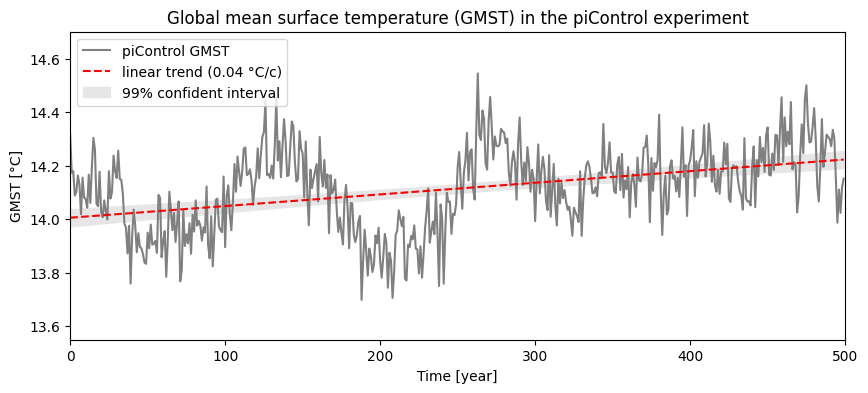

In [109]:
ts = piCtrl['ts'].groupby('time.year').mean() - 273.15  # K to °C
x  = ts['year'].data

# plot
fig, ax = plt.subplots(1,1, figsize=(10, 4))

ax.plot( ts['year']-1850, ts, c=(0.5,0.5,0.5), label='piControl GMST')

# compute linear trend
lin_reg = scipy.stats.linregress(ts['year'], ts)
ts_pred = lin_reg.slope * ts['year'] + lin_reg.intercept

# compute 99% confidence interval
alpha   = 0.01
tvalue  = scipy.stats.t.ppf( 1 - (alpha/2), len(ts)-2 )  # Student test
stderr  = lin_reg.stderr * np.sqrt(np.var(ts['year'].data, ddof=1)*(len(ts)-1))

ts_conf = stderr * (np.sqrt( (1/len(ts)) + ((x - np.mean(x))**2)/np.sum((x-np.mean(x))**2)))

# plot lines
ax.plot( ts['year']-1850, ts_pred, ls='--', c='r', 
                                label=r'linear trend ({:.2f} °C/c)'.format(lin_reg.slope*100))

ax.fill_between( ts['year']-1850, ts_pred+(tvalue*ts_conf), ts_pred-(tvalue*ts_conf), 
                                            color=(.9,.9,.9), label='99% confident interval')

# axe properties
ax.set_xlim((0, 500))
ax.set_ylim((13.55, 14.7))
ax.set_xlabel('Time [year]')
ax.set_ylabel('GMST [°C]')

ax.legend(loc=2)

_ = ax.set_title("Global mean surface temperature (GMST) in the piControl experiment")

#### Question 8: 

* _Plot the timeseries for the historical experiment (from 1850 to 2014)._
* _Compute the linear trends and the 95% of confidence range for three distinct periods (1850-2014, 1970-2009, 2005-2014)._
* _Interpret the differences._


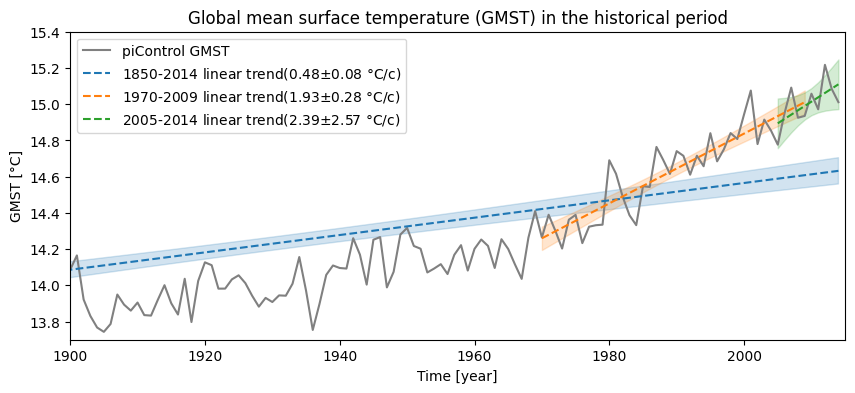

In [138]:
ts = histrc['r1']['ts'] - 273.15  # K to °C

# plot
fig, ax = plt.subplots(1,1, figsize=(10, 4))

ax.plot( ts['year'], ts, c=(0.5,0.5,0.5), label='piControl GMST')


# compute linear trend over different period
list_errors = []
list_colors = ['tab:blue', 'tab:orange', 'tab:green']

for i, per in enumerate([(0, None), (120,-5), (-10, None)]) :
    y       = ts[per[0]:per[1]]
    x       = ts['year'][per[0]:per[1]].data
    
    lin_reg = scipy.stats.linregress(x, y)
    ts_pred = lin_reg.slope * x + lin_reg.intercept

    # compute 95% confidence interval
    alpha   = 0.05
    tvalue  = scipy.stats.t.ppf( 1 - (alpha/2), len(y)-2 )  # Student test
    stderr  = lin_reg.stderr * np.sqrt(np.var(x, ddof=1)*(len(y)-1))

    ts_conf = stderr * (np.sqrt( (1/len(y)) + ((x - np.mean(x))**2)/np.sum((x-np.mean(x))**2)))
        
    # plot lines
    color  = list_colors[i]
    ltext  = '{}-{} linear trend'.format(x[0], x[-1])
    ltext += r'({:.2f}$\pm${:.2f} °C/c)'.format(lin_reg.slope*100, tvalue*lin_reg.stderr*100)
    
    ax.plot( x, ts_pred, ls='--', c=color, label=ltext)

    ax.fill_between( x, ts_pred+(tvalue*ts_conf), ts_pred-(tvalue*ts_conf), 
                                                color=color, alpha=0.2)


# axe properties
ax.set_xlim((1900, 2015))
ax.set_ylim((13.7, 15.4))
ax.set_xlabel('Time [year]')
ax.set_ylabel('GMST [°C]')

ax.legend(loc=2)

_ = ax.set_title("Global mean surface temperature (GMST) in the historical period")

#### Question 9: 

* _Compare the simulated global mean surface temperature evolution with the estimation from observations._
* _Try with different historical run (member). What do you observe ?_ 


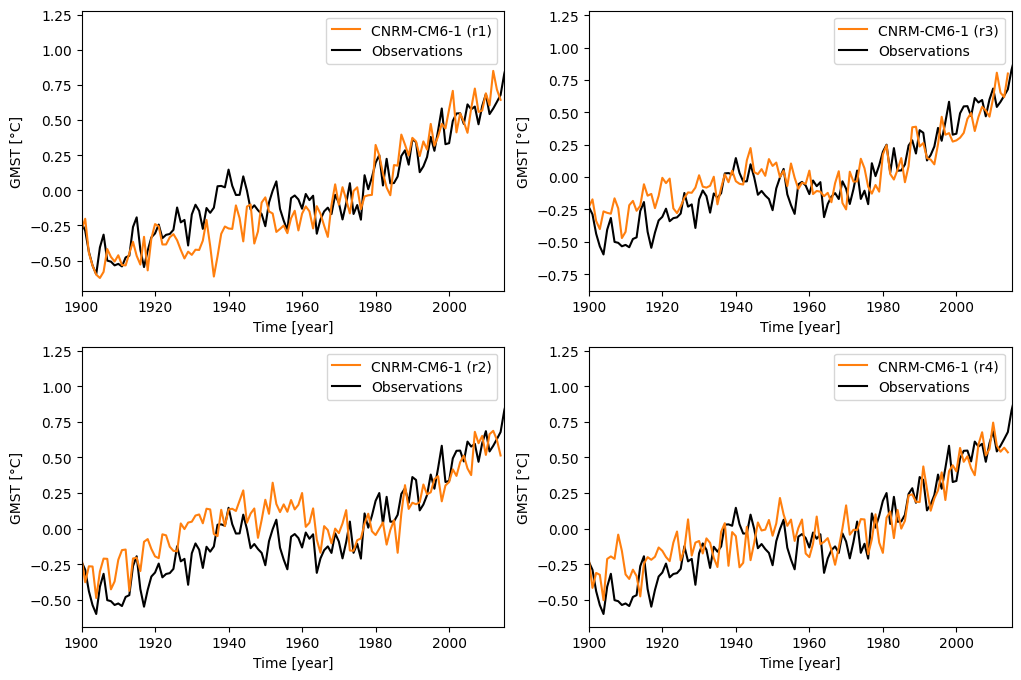

In [168]:
# plot
fig, axes = plt.subplots(2,2, figsize=(12, 8))

for i, r in enumerate(['r1', 'r2', 'r3', 'r4']):
    ax    = axes[i%2, i//2]
    
    # CNRM-CM6-1
    ts    = histrc[r]['ts'] - 273.15  # K to °C
    tmean = ts[111:140].mean()

    ax.plot( ts['year'], ts - tmean, color='tab:orange', label='CNRM-CM6-1 ({})'.format(r))

    # Observation
    years    = np.array([d.year for d in HadCrut5['time'].data])

    ax.plot( years, GSAT, color='k', label='Observations', zorder=0)


    # axe properties
    ax.set_xlim((1900, 2015))
    ax.set_ylim((None, None))
    ax.set_xlabel('Time [year]')
    ax.set_ylabel('GMST [°C]')

    ax.legend()

#_ = ax.set_title("Global surface air temperature (GSAT) anomalies relative to 1961-1990")

#### Question 10: 

* _Based on your last result, propose a method to deal with the ensemble members_.

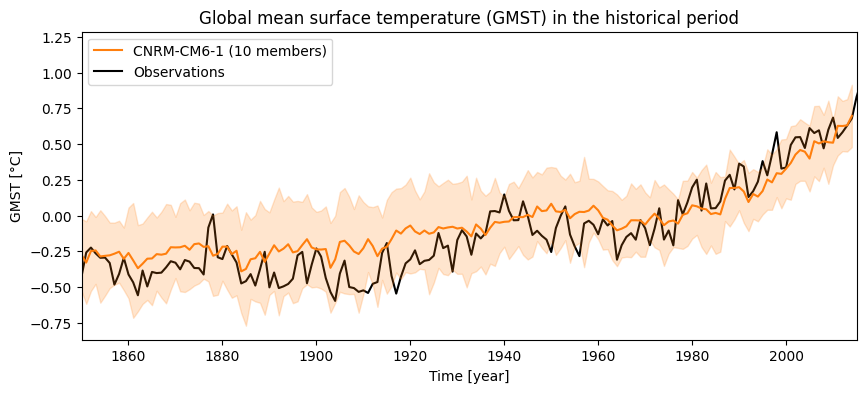

In [195]:
# plot
fig, ax = plt.subplots(1,1, figsize=(10, 4))

# size of the ensemble
n_members = 10

# CNRM-CM6-1 ensemble
arrays   = [histrc[r]['ts'] for r in list(histrc.keys())[:n_members]]
ensemble = xr.concat( arrays, dim='member') - 273.15

ts_cnrm  = ensemble.mean('member')
tmean    = ts_cnrm[111:140].mean()

ax.plot( ts_cnrm['year'], ts_cnrm - tmean, color='tab:orange', 
                        label='CNRM-CM6-1 ({} members)'.format(len(ensemble['member'])) )

var_cnrm = 1.64*ensemble.std('member')

ax.fill_between( ts_cnrm['year'], ts_cnrm - tmean + var_cnrm, ts_cnrm - tmean - var_cnrm, 
                                            color='tab:orange', alpha=0.2)
        
# Observation
years    = np.array([d.year for d in HadCrut5['time'].data])

ax.plot( years, GSAT, color='k', label='Observations', zorder=0)


# axe properties
ax.set_xlim((1850, 2015))
#ax.set_ylim((13.7, 15.4))
ax.set_xlabel('Time [year]')
ax.set_ylabel('GMST [°C]')

ax.legend(loc=2)

_ = ax.set_title("Global mean surface temperature (GMST) in the historical period")

<a id="section-3"></a>
## 3. Détection and attribution 


In the previous sections, we have analyzed the Earth energy balance and showed how the climate respond to an external CO$_2$ forcing. We will now try to understand the mechanisms that drive this response.

Climate feedbacks are internal mechanisms which can alter the response to an initial perturbation. We call a _positive_ and _negative_ feedback when the mechanism tends to amply or diminish the response, respectively.

#### Question 1: 

* _After having define the Earth climate system, write its energy budget (0D) and add an illustration of the model_
* _How is defined the equilibrium ?_

__Help__: you can insert Latex math code using '$' symbols and insert image using html code:
```html
<img src="image.png" alt="drawing" width="400"/>
```


## 4. Conclusion and discussion

We conclude the notebook by using output from another CMIP6 model. The following lines, will load global overaged monthly outputs from the ACCESS-CM2 climate model [(Bi et al., 2020)](https://connectsci.au/es/article/70/1/225/73456/Configuration-and-spin-up-of-ACCESS-CM2-the-new)) developped by the Australian climate modelling community:   


```python
# initialize empty dict to store variables
piCtrl_cm2 = dict()
abrupt_cm2 = dict()

# load netCDF (.nc) files using xarray
for f in os.listdir("../data/CMIP6"):
    var   = f.split('_')[0]
    model = f.split('_')[2]
    expe  = f.split('_')[3]
    
    # select only ACCESS-CM2 model
    if model == 'ACCESS-CM2':
        ds = xr.load_dataset(os.path.join("../data/CMIP6", f), use_cftime=True)
        
        if expe == 'piControl':
            piCtrl_cm2[var]      = ds[list(ds.variables)[-1]]
            piCtrl_cm2[var].name = var
        elif expe == 'abrupt-4xCO2':
            abrupt_cm2[var]      = ds[list(ds.variables)[-1]]
            abrupt_cm2[var].name = var
            
print("Variables loaded in piCtrl_cm2: \n", list(piCtrl_cm2.keys()))
print("")
print("Variables loaded in abrupt_cm2: \n", list(abrupt_cm2.keys())) 
```